# Handwritten Digit Recognition Demonstration

Use the two frozen project models to recognise the **same selected MNIST image**. Handwritten digit recognition means assigning a grayscale image to a digit category from 0 to 9.

This is an illustrative demonstration using the **original training partition**, not a new accuracy experiment. Some displayed examples may have been used to fit the models. The official test arrays returned by the required loader are immediately discarded; no final test predictions or metrics are repeated.

Run all cells once from the repository root with the documented Python 3.11 kernel. Then change only `sample_index` in **Choose an image** and rerun that cell and all following code cells. Indices are selected directly, not filtered by prediction correctness. No model is trained, tuned or saved here.


## 1. Portable setup

The default cache is `.keras/datasets/mnist.npz` inside this repository. Set the optional **MNIST_KERAS_HOME** environment variable before starting the kernel if an existing Keras cache should be reused; its value is the directory containing `datasets/`. The notebook sets KERAS_HOME **before importing TensorFlow** and does not print a private cache location.

If the cache is absent, the required Keras loader downloads MNIST on its first run, so internet access is needed. Keep the dataset cache out of Git. No package installation occurs in this notebook.


In [1]:
import os
import sys
import json
import hashlib
import importlib.metadata

assert sys.version_info[:2] == (3, 11), 'Select the documented Python 3.11 kernel.'
project_dir = os.path.abspath(os.getcwd())
assert os.path.isfile(os.path.join(project_dir, 'MNIST_Demonstration.ipynb')), 'Start from the repository root.'
keras_home = os.path.abspath(os.environ.get('MNIST_KERAS_HOME', os.path.join(project_dir, '.keras')))
os.environ['KERAS_HOME'] = keras_home
os.environ['MPLCONFIGDIR'] = os.path.join(project_dir, '.cache', 'matplotlib')
dataset_path = os.path.join(keras_home, 'datasets', 'mnist.npz')
print('Python version:', sys.version.split()[0])
print('Cache configured before TensorFlow import; private paths are not displayed.')


Python version: 3.11.17
Cache configured before TensorFlow import; private paths are not displayed.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import tensorflow as tf
import joblib

seaborn.set()
versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'pandas', 'matplotlib', 'seaborn', 'tensorflow', 'keras', 'scikit-learn', 'joblib']}
print(versions)


{'numpy': '2.4.6', 'pandas': '3.1.0', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


## 2. Verify and load the saved models

Load only the trusted project artifacts under `models/`. Their SHA-256 hashes must match the verified final-evaluation record before loading. The network must be the selected **100/100 hidden-unit model with ten outputs**.

Native model loading and hash checks are necessary project additions. The lecturer demonstrated prediction, while saving/loading these model formats was explained in earlier project stages. `compile=False` loads the network for prediction without creating a new training procedure.


In [3]:
models_dir = os.path.realpath(os.path.join(project_dir, 'models'))
lr_path = os.path.realpath(os.path.join(models_dir, 'logistic_regression.joblib'))
nn_path = os.path.realpath(os.path.join(models_dir, 'neural_network.keras'))
assert os.path.dirname(lr_path) == models_dir
assert os.path.dirname(nn_path) == models_dir
assert os.path.isfile(lr_path) and os.path.isfile(nn_path)

with open(os.path.join(project_dir, 'results', 'stage4', 'frozen_models_before_evaluation.json'), encoding='utf-8') as file:
    frozen = json.load(file)
with open(os.path.join(project_dir, 'results', 'stage3', 'selected_settings.json'), encoding='utf-8') as file:
    selected_settings = json.load(file)
model_hashes_before = {}
for filename in ['logistic_regression.joblib', 'neural_network.keras']:
    with open(os.path.join(models_dir, filename), 'rb') as file:
        model_hashes_before[filename] = hashlib.sha256(file.read()).hexdigest()
    assert model_hashes_before[filename] == frozen['models'][filename]['sha256_before']
assert selected_settings == frozen['neural_network_settings']
print('Both frozen model hashes match the verified records.')


Both frozen model hashes match the verified records.


In [4]:
assert versions['scikit-learn'] == '1.9.1'
assert versions['tensorflow'] == '2.21.0' and versions['keras'] == '3.15.1'
reg_log = joblib.load(lr_path)
model = tf.keras.models.load_model(nn_path, compile=False)
assert reg_log.n_features_in_ == 784
assert np.array_equal(reg_log.classes_, np.arange(10))
assert model.input_shape == (None, 28, 28)
assert model.output_shape == (None, 10)
assert [layer.units for layer in model.layers if hasattr(layer, 'units')] == [100, 100, 10]
assert selected_settings['hidden_units_per_layer'] == 100
lr_weights_before = hashlib.sha256(reg_log.coef_.tobytes() + reg_log.intercept_.tobytes()).hexdigest()
nn_weights_before = hashlib.sha256(b''.join(weights.tobytes() for weights in model.get_weights())).hexdigest()
print('Logistic Regression loaded: 784 pixel features.')
print('Selected Neural Network loaded: 100/100 hidden units, ten digit outputs.')


Logistic Regression loaded: 784 pixel features.
Selected Neural Network loaded: 100/100 hidden units, ten digit outputs.


## 3. Load MNIST

Use the required `tf.keras.datasets.mnist.load_data()` call. Keep only the original 60,000 training images and their labels for the demonstration. The second returned partition is discarded without exploring or predicting it.


In [5]:
cache_was_present = os.path.isfile(dataset_path)
(x_train, y_train), unused_test_partition = tf.keras.datasets.mnist.load_data()
del unused_test_partition
assert x_train.shape == (60000, 28, 28)
assert y_train.shape == (60000,)
assert x_train.dtype == np.uint8 and np.issubdtype(y_train.dtype, np.integer)
with open(dataset_path, 'rb') as file:
    dataset_sha256 = hashlib.sha256(file.read()).hexdigest()
assert dataset_sha256 == frozen['dataset_sha256']
print('Used existing local MNIST cache.' if cache_was_present else 'MNIST downloaded into the configured local cache.')
print('Demonstration partition: original training images', x_train.shape)


Used existing local MNIST cache.
Demonstration partition: original training images (60000, 28, 28)


## 4. Choose an image

Set `sample_index` to an integer from **0 to 59999**. Zero selects the first original training image. Rerun the selection cell and the following cells after changing it; there is no search for a correctly predicted example.


In [6]:
sample_index = 0


Selected original training index: 0
Actual digit: 5


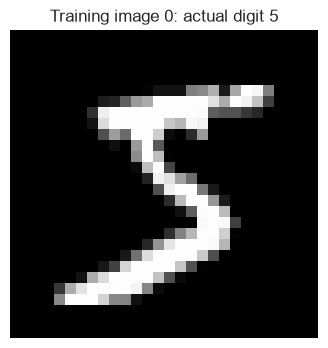

In [7]:
assert isinstance(sample_index, int) and 0 <= sample_index < len(x_train), 'Choose an integer from 0 to 59999.'
image = x_train[sample_index]
actual_digit = int(y_train[sample_index])
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Training image {0}: actual digit {1}'.format(sample_index, actual_digit))
plt.axis('off')
plt.show()
print('Selected original training index:', sample_index)
print('Actual digit:', actual_digit)


## 5. Prepare that same image for both models

An image is a **28 × 28 matrix** of 784 numerical pixels: zero is black and 255 is white. Convert it to float32 and divide by 255 so values lie in [0,1], exactly as during training.

Logistic Regression expects one row containing **784 features**, so its input shape is `(1,784)`. The network expects `(1,28,28)`: the first dimension is a batch containing one image, and its saved Flatten layer rearranges the pixels internally.

The two representations below share the same normalised pixel data. Reshaping changes arrangement, not image content. No label or model setting is used to change the image.


In [8]:
inputs = image.astype(np.float32)
inputs /= 255.
inputs = inputs.reshape(1, 28, 28)
x = inputs.reshape(1, 784)
assert inputs.dtype == x.dtype == np.float32
assert inputs.shape == (1, 28, 28) and x.shape == (1, 784)
assert np.shares_memory(x, inputs)
assert np.array_equal(x.reshape(1, 28, 28), inputs)
assert np.array_equal(np.rint(inputs[0] * 255).astype(np.uint8), image)
assert 0 <= inputs.min() <= inputs.max() <= 1
print('Logistic Regression input:', x.shape, x.dtype)
print('Neural Network input:', inputs.shape, inputs.dtype)
print('Both inputs contain the same image; pixel range:', inputs.min(), inputs.max())


Logistic Regression input: (1, 784) float32
Neural Network input: (1, 28, 28) float32
Both inputs contain the same image; pixel range: 0.0 1.0


## 6. Make and compare predictions

Logistic Regression combines learned pixel weights and an intercept into ten class scores and selects the most likely digit.

The network's hidden neurons combine learned weights and biases, then ReLU introduces nonlinearity. The ten-output Softmax layer produces probabilities for digits 0–9. `argmax(axis=1)` selects the largest probability in the one-image batch. This multiclass step replaces a binary cutoff; it was introduced explicitly in the project.

The actual label is used only for the displayed comparison. A match for a demonstration image is not a new accuracy estimate.


In [9]:
logistic_prediction = int(reg_log.predict(x)[0])
neural_probabilities = model.predict(inputs, verbose=0)
assert neural_probabilities.shape == (1, 10)
assert np.isfinite(neural_probabilities).all()
assert (neural_probabilities >= 0).all() and (neural_probabilities <= 1).all()
assert np.allclose(neural_probabilities.sum(axis=1), 1, atol=1e-5)
neural_prediction = int(np.argmax(neural_probabilities, axis=1)[0])
assert 0 <= logistic_prediction <= 9 and 0 <= neural_prediction <= 9

predictions = pd.DataFrame({
    'Model': ['Logistic Regression', 'Selected Neural Network (100/100)'],
    'Actual digit': [actual_digit, actual_digit],
    'Predicted digit': [logistic_prediction, neural_prediction],
    'Matches actual label': [logistic_prediction == actual_digit, neural_prediction == actual_digit]
})
print('Predictions for the same original training image:', sample_index)
predictions


Predictions for the same original training image: 0


                               Model  ...  Matches actual label
0                Logistic Regression  ...                  True
1  Selected Neural Network (100/100)  ...                  True

[2 rows x 4 columns]


The network's ten probabilities are shown below. They sum approximately to one, but a large probability is not a guarantee that the digit is correct.


In [10]:
pd.DataFrame({'Digit': np.arange(10), 'Neural Network probability': neural_probabilities[0]})


   Digit  Neural Network probability
0      0                3.620278e-08
1      1                1.439669e-07
2      2                2.319304e-05
3      3                7.134916e-02
4      4                4.150926e-14
5      5                9.286266e-01
6      6                1.197132e-10
7      7                2.666727e-07
8      8                4.082232e-10
9      9                6.681799e-07


## 7. Confirm preservation

Prediction must not change either saved model or its learned parameters. These checks compare the hashes recorded before this demonstration. No `.fit()`, tuning, model saving or final evaluation is performed.


In [11]:
for filename in ['logistic_regression.joblib', 'neural_network.keras']:
    with open(os.path.join(models_dir, filename), 'rb') as file:
        assert hashlib.sha256(file.read()).hexdigest() == model_hashes_before[filename]
assert hashlib.sha256(reg_log.coef_.tobytes() + reg_log.intercept_.tobytes()).hexdigest() == lr_weights_before
assert hashlib.sha256(b''.join(weights.tobytes() for weights in model.get_weights())).hexdigest() == nn_weights_before
print('Frozen model files and learned weights remain unchanged.')


Frozen model files and learned weights remain unchanged.


## Why an incorrect prediction can occur

People form loops, angles and strokes differently; some shapes resemble other digits. Logistic Regression uses linear class scores, while the network applies nonlinear hidden transformations. Both can make mistakes. These are possible explanations, not proof of the reason for a specific decision.

Do not change the models in response to demonstration outcomes. The final test comparison stays in the existing evaluation records, separate from these illustrative training-partition examples.


## Classroom-method evidence and additions

Cell numbers are one-based notebook positions, including Markdown and empty cells.

| Pattern | Lecturer's original notebook and cells |
|---|---|
| Familiar imports and names | `Bank_Logistic_Regression.ipynb`, 1, 5–6; `linear regression.ipynb`, 1 |
| Float32 and division by 255 | `Untitled19.ipynb`, 3 |
| NumPy reshape | `Untitled13.ipynb`, 16–17, 46 |
| Prediction | `Bank_Data_Logistic_Regression (1).ipynb`, 8, 18–19; `Untitled18.ipynb`, 8 |
| Sequential hidden-layer/Softmax reasoning | `Untitled19.ipynb`, 7; its output-width mistake was corrected in the project |
| Matplotlib labels and display | `linear regression.ipynb`, 6; grayscale image display is explicitly required by the project PDF, page 2 |

The required Keras loader, Scikit-learn multiclass API, native model loading, hash checks and argmax are documented adaptations or project additions. This notebook uses direct sequential cells, rather than new classes, custom functions, interactive libraries or a web interface.


## Actual execution observations

All eleven code cells ran successfully using Python 3.11.17 in the dedicated project environment. Both frozen models loaded, and the saved view above shows sample_index = 0. Changing the index and rerunning the following cells was verified for eight indices fixed before inference.

| Original training index | Actual digit | Logistic Regression | Selected Neural Network |
|---|---:|---:|---:|
| 0 | 5 | 5 | 5 |
| 1 | 0 | 0 | 0 |
| 2 | 4 | 4 | 4 |
| 10 | 3 | 3 | 3 |
| 100 | 5 | 5 | 5 |
| 1000 | 0 | 0 | 0 |
| 10000 | 3 | 3 | 3 |
| 59999 | 8 | 8 | 8 |

Every selected image was supplied to both models with shapes (1,784) and (1,28,28), using float32 pixels divided by 255. Model files and weights remained unchanged. The local cache was used without network attempts. No final test prediction, final metric recalculation or training took place.

The rows are illustrative outcomes, not a new accuracy estimate. See docs/demonstration_verification.json for the execution record.
